In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid")

df = pd.read_csv('training-data.csv')

df.head()

,Id,Income,Age,Experience,Married/Single,House_Ownership,Car_Ownership,Profession,CITY,STATE,CURRENT_JOB_YRS,CURRENT_HOUSE_YRS,Risk_Flag
0,1,1303834,23,3,single,rented,no,Mechanical_engineer,Rewa,Madhya_Pradesh,3,13,0
1,2,7574516,40,10,single,rented,no,Software_Developer,Parbhani,Maharashtra,9,13,0
2,3,3991815,66,4,married,rented,no,Technical_writer,Alappuzha,Kerala,4,10,0
3,4,6256451,41,2,single,rented,yes,Software_Developer,Bhubaneswar,Odisha,2,12,1
4,5,5768871,47,11,single,rented,no,Civil_servant,Tiruchirappalli[10],Tamil_Nadu,3,14,1


In [2]:
print("Shape of dataset:", df.shape)
df.info()
df.isnull().sum()

Shape of dataset: (252000, 13)
<class 'pandas.DataFrame'>
RangeIndex: 252000 entries, 0 to 251999
Data columns (total 13 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   Id                 252000 non-null  int64
 1   Income             252000 non-null  int64
 2   Age                252000 non-null  int64
 3   Experience         252000 non-null  int64
 4   Married/Single     252000 non-null  str  
 5   House_Ownership    252000 non-null  str  
 6   Car_Ownership      252000 non-null  str  
 7   Profession         252000 non-null  str  
 8   CITY               252000 non-null  str  
 9   STATE              252000 non-null  str  
 10  CURRENT_JOB_YRS    252000 non-null  int64
 11  CURRENT_HOUSE_YRS  252000 non-null  int64
 12  Risk_Flag          252000 non-null  int64
dtypes: int64(7), str(6)
memory usage: 36.0 MB


Id                   0
Income               0
Age                  0
Experience           0
Married/Single       0
House_Ownership      0
Car_Ownership        0
Profession           0
CITY                 0
STATE                0
CURRENT_JOB_YRS      0
CURRENT_HOUSE_YRS    0
Risk_Flag            0
dtype: int64

In [3]:
df.describe()

,Id,Income,Age,Experience,CURRENT_JOB_YRS,CURRENT_HOUSE_YRS,Risk_Flag
count,252000.000000,2.520000e+05,252000.000000,252000.000000,252000.000000,252000.000000,252000.000000
mean,126000.500000,4.997117e+06,49.954071,10.084437,6.333877,11.997794,0.123000
std,72746.278255,2.878311e+06,17.063855,6.002590,3.647053,1.399037,0.328438
min,1.000000,1.031000e+04,21.000000,0.000000,0.000000,10.000000,0.000000
25%,63000.750000,2.503015e+06,35.000000,5.000000,3.000000,11.000000,0.000000
50%,126000.500000,5.000694e+06,50.000000,10.000000,6.000000,12.000000,0.000000
75%,189000.250000,7.477502e+06,65.000000,15.000000,9.000000,13.000000,0.000000
max,252000.000000,9.999938e+06,79.000000,20.000000,14.000000,14.000000,1.000000


Index(['Id', 'Income', 'Age', 'Experience', 'Married/Single',
       'House_Ownership', 'Car_Ownership', 'Profession', 'CITY', 'STATE',
       'CURRENT_JOB_YRS', 'CURRENT_HOUSE_YRS', 'Risk_Flag'],
      dtype='str')


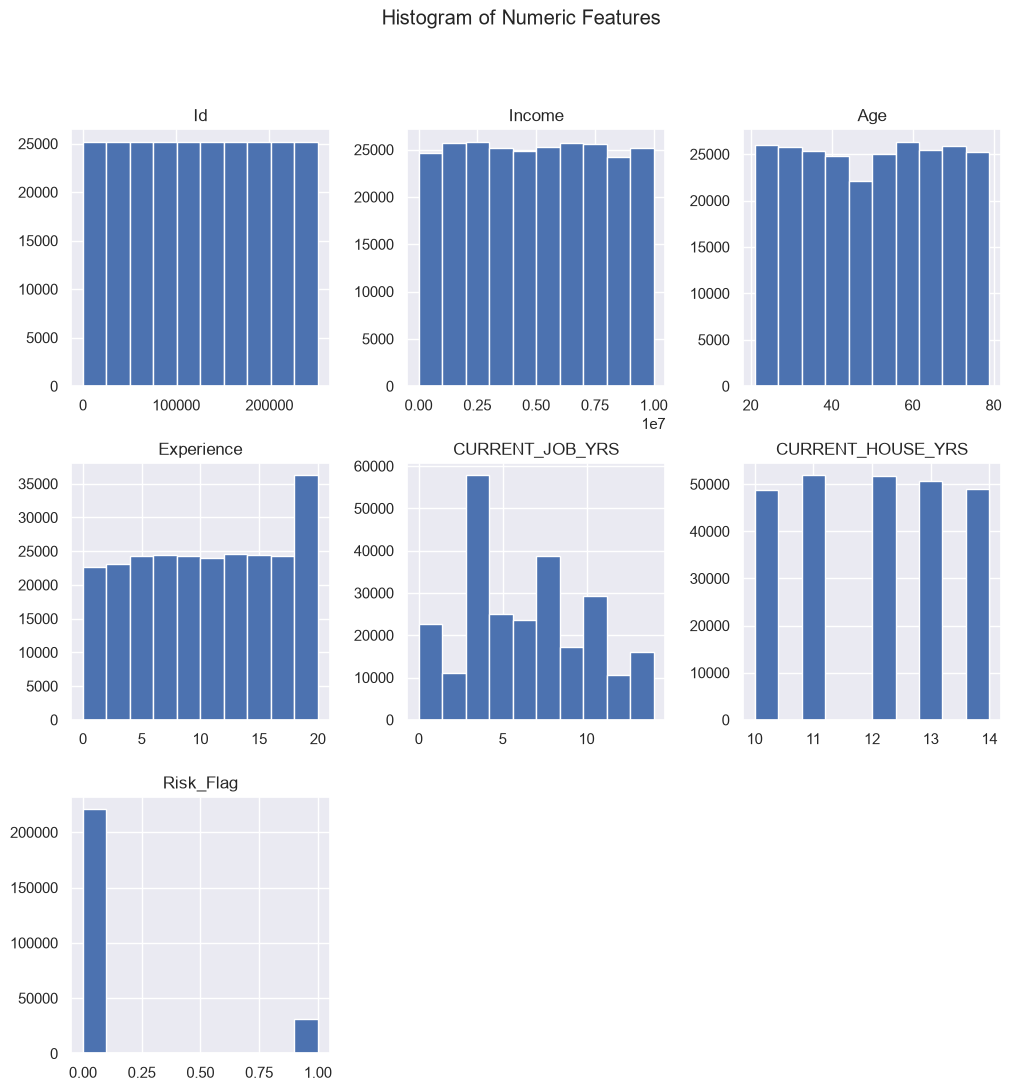

In [4]:
print(df.columns)

df.hist(figsize=(12, 12))
plt.suptitle("Histogram of Numeric Features")
plt.show()

Risk_Flag
0    221004
1     30996
Name: count, dtype: int64


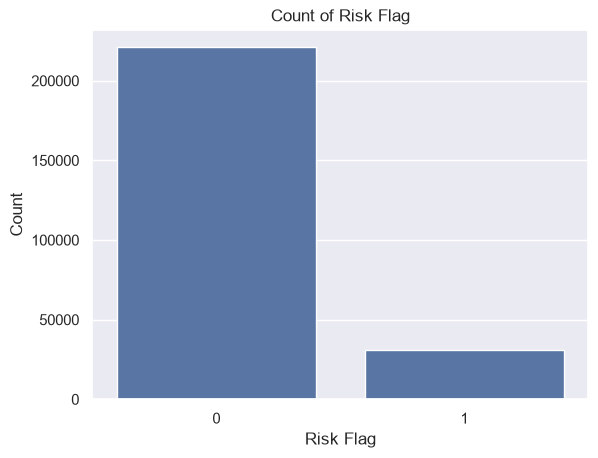

In [5]:
print(df['Risk_Flag'].value_counts())

sns.countplot(x='Risk_Flag', data=df)
plt.title("Count of Risk Flag")
plt.xlabel("Risk Flag")
plt.ylabel("Count")
plt.show()

Married/Single
single     226272
married     25728
Name: count, dtype: int64


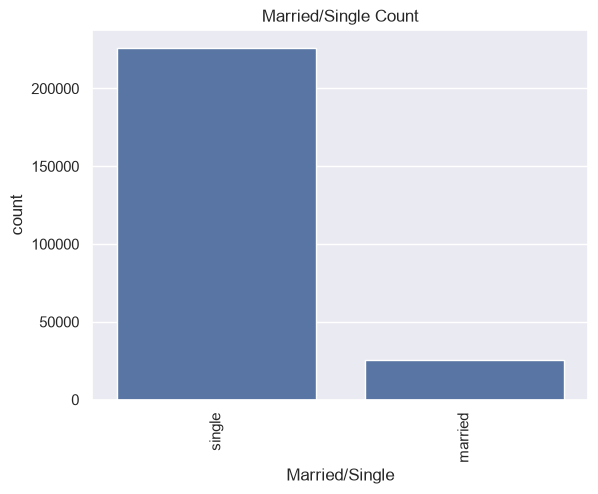

House_Ownership
rented          231898
owned            12918
norent_noown      7184
Name: count, dtype: int64


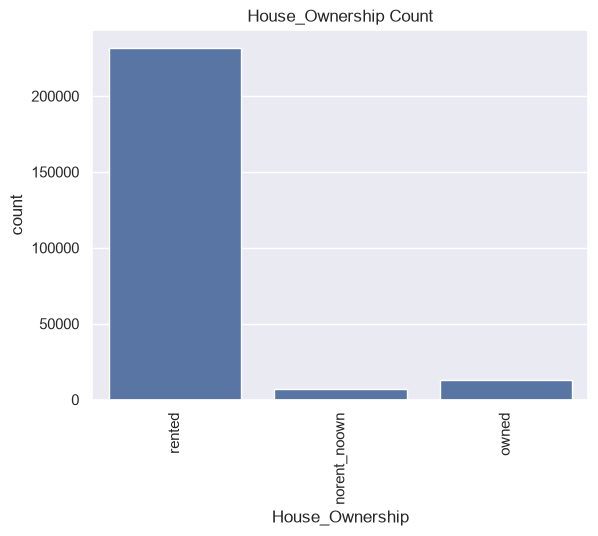

Car_Ownership
no     176000
yes     76000
Name: count, dtype: int64


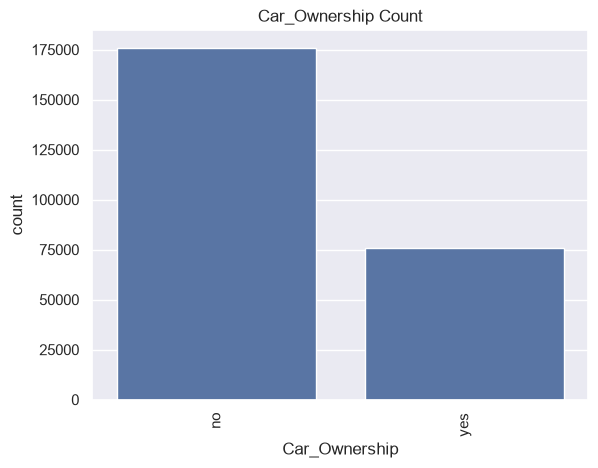

In [6]:
def explore_categorical(feature):
    print(df[feature].value_counts())
    sns.countplot(x=feature, data=df)
    plt.title(f'{feature} Count')
    plt.xticks(rotation=90)
    plt.show()

categorical_cols = ['Married/Single', 'House_Ownership', 'Car_Ownership']
for col in categorical_cols:
    explore_categorical(col)

In [7]:
print(f"Unique States: {df['STATE'].nunique()}")
print(df['STATE'].value_counts())

print(f"Unique Professions: {df['Profession'].nunique()}")
print(df['Profession'].value_counts())


Unique States: 29
STATE
Uttar_Pradesh        28400
Maharashtra          25562
Andhra_Pradesh       25297
West_Bengal          23483
Bihar                19780
Tamil_Nadu           16537
Madhya_Pradesh       14122
Karnataka            11855
Gujarat              11408
Rajasthan             9174
Jharkhand             8965
Haryana               7890
Telangana             7524
Assam                 7062
Kerala                5805
Delhi                 5490
Punjab                4720
Odisha                4658
Chhattisgarh          3834
Uttarakhand           1874
Jammu_and_Kashmir     1780
Puducherry            1433
Mizoram                849
Manipur                849
Himachal_Pradesh       833
Tripura                809
Uttar_Pradesh[5]       743
Chandigarh             656
Sikkim                 608
Name: count, dtype: int64
Unique Professions: 51
Profession
Physician                     5957
Statistician                  5806
Web_designer                  5397
Psychologist                

## 2. EDA and Feature Relationship

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

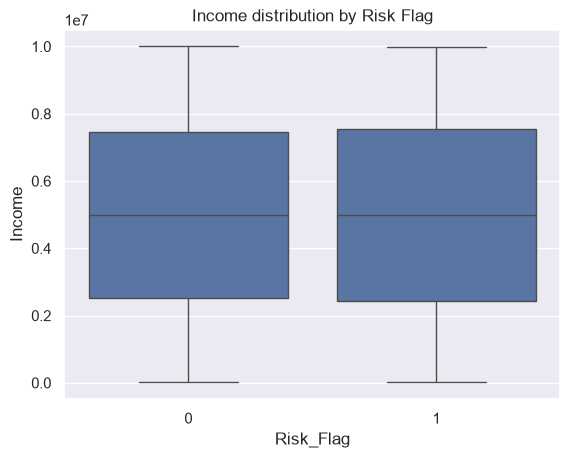

In [9]:
sns.boxplot(x='Risk_Flag', y='Income', data=df)
plt.title("Income distribution by Risk Flag")
plt.show()

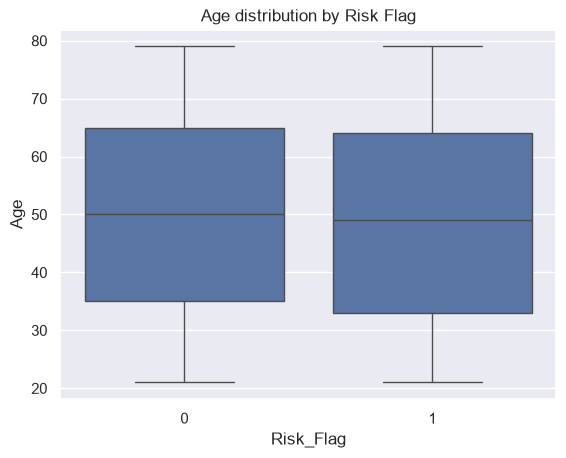

In [10]:
sns.boxplot(x="Risk_Flag", y="Age", data=df)
plt.title("Age distribution by Risk Flag")
plt.show()

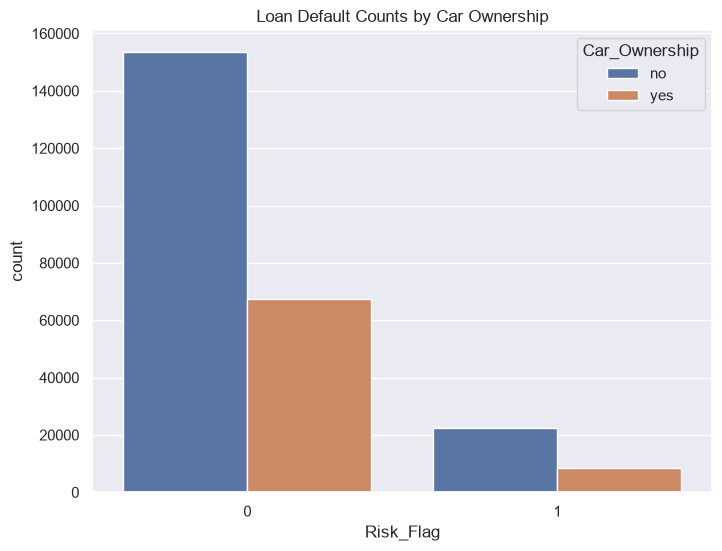

In [11]:
fig, ax = plt.subplots(figsize=(8,6))
sns.countplot(x="Risk_Flag", hue="Car_Ownership", data=df, ax=ax)
plt.title("Loan Default Counts by Car Ownership")
plt.show()

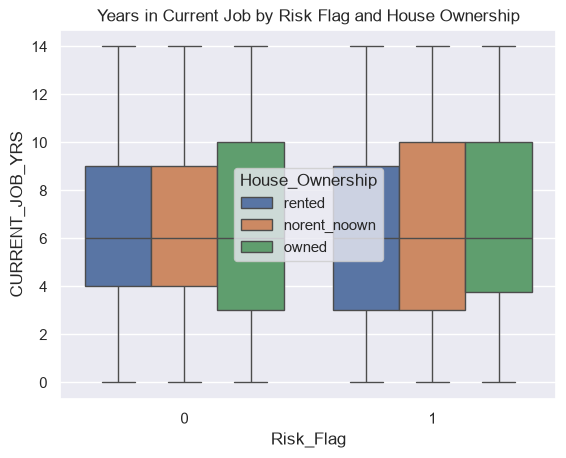

In [12]:
sns.boxplot(x="Risk_Flag", y="CURRENT_JOB_YRS", hue="House_Ownership", data=df)
plt.title("Years in Current Job by Risk Flag and House Ownership")
plt.show()

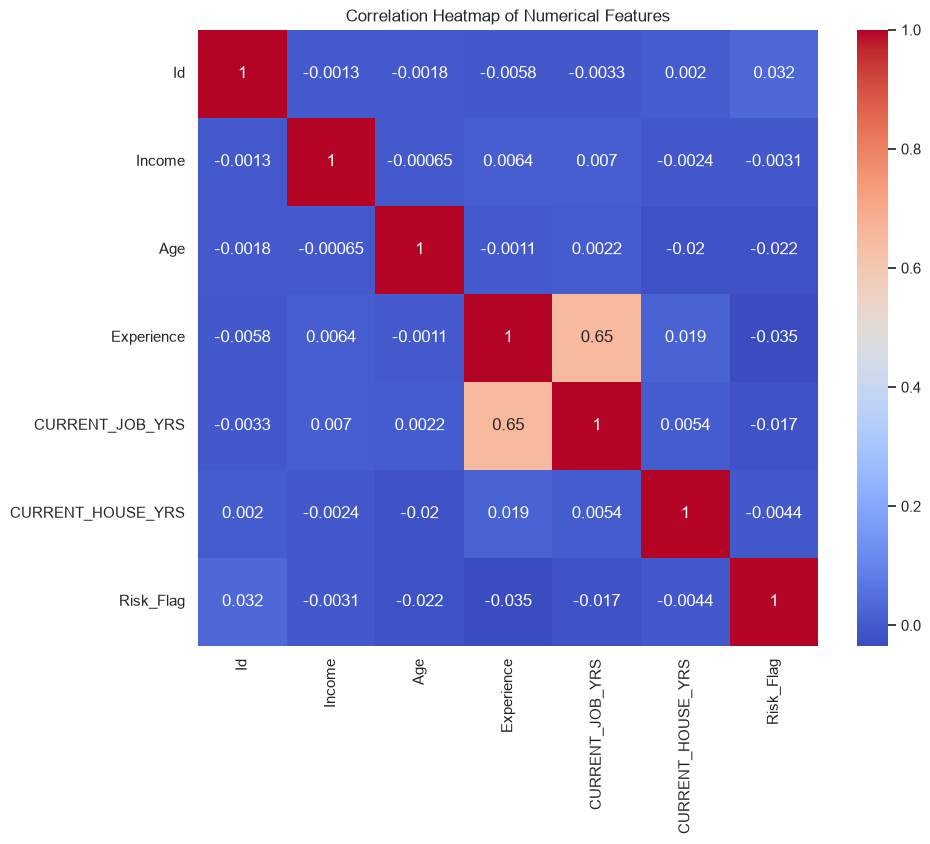

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
df = pd.read_csv('training-data.csv')

plt.figure(figsize=(10,8))
sns.heatmap(df.select_dtypes(include=['int64', 'float64']).corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

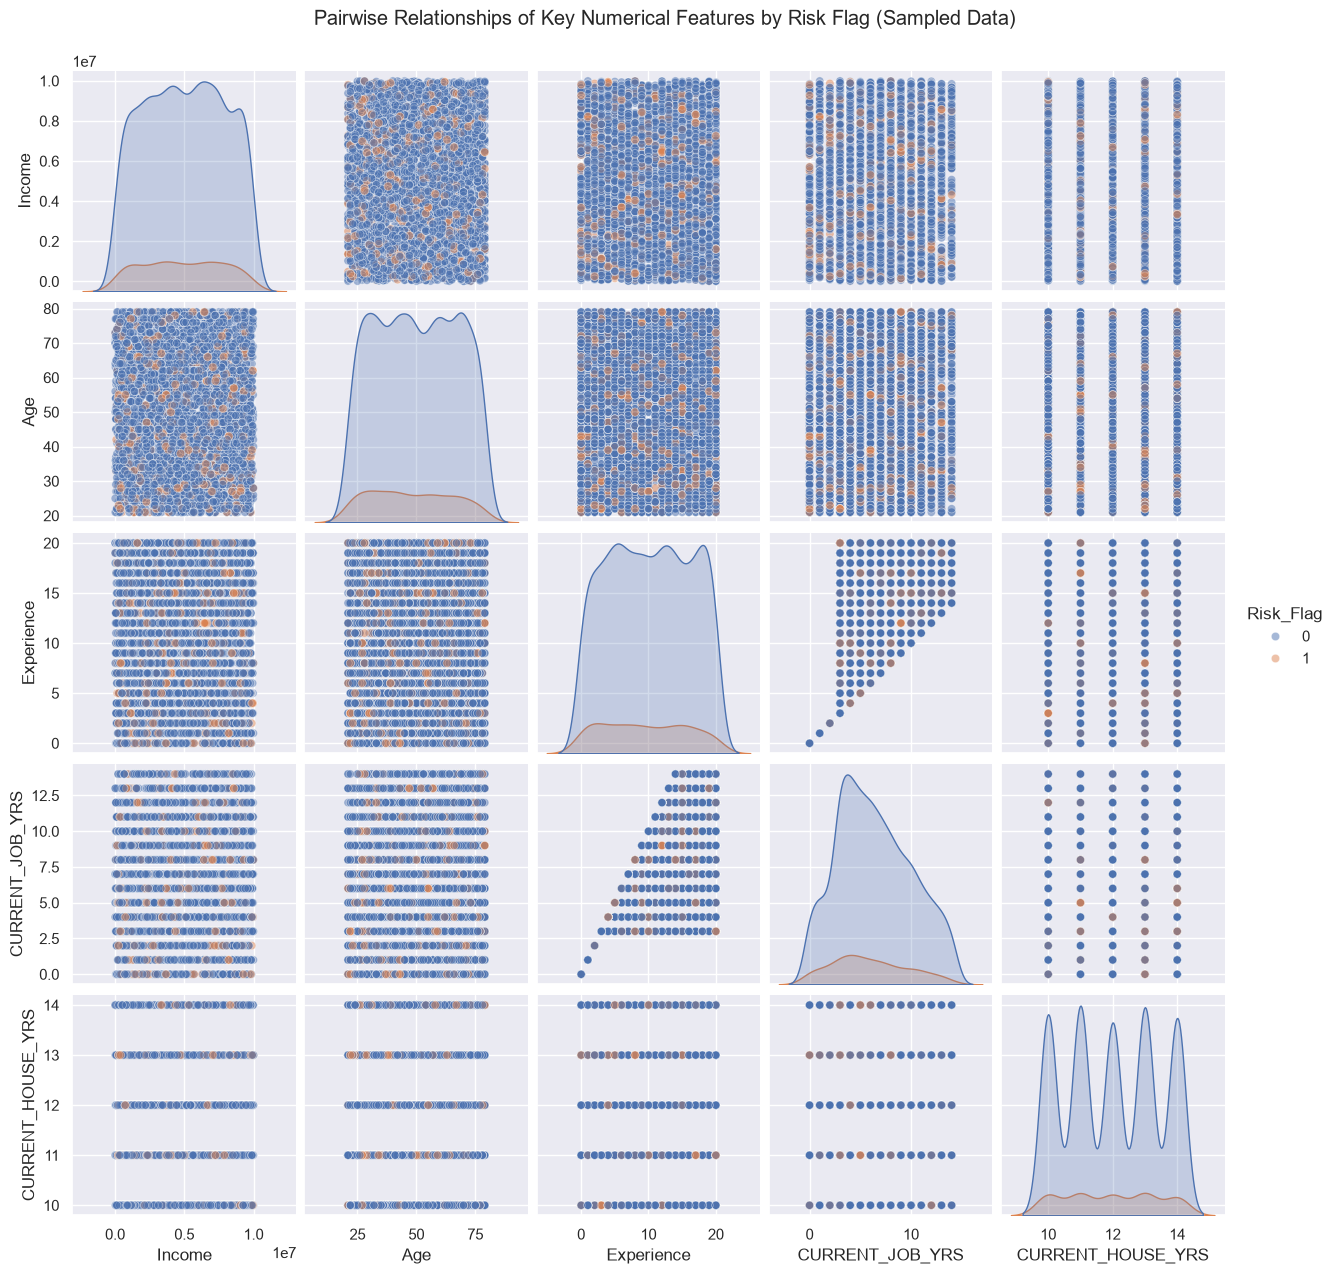

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
df = pd.read_csv('training-data.csv')

sample_df = df[['Income', 'Age', 'Experience', 'CURRENT_JOB_YRS', 'CURRENT_HOUSE_YRS', 'Risk_Flag']].sample(5000, random_state=42)

sns.pairplot(sample_df, hue='Risk_Flag', diag_kind='kde', plot_kws={'alpha':0.5})
plt.suptitle("Pairwise Relationships of Key Numerical Features by Risk Flag (Sampled Data)", y=1.02)
plt.show()


## 3 - Encoding Categorical Variables & Data Splitting¶

In [15]:

from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [16]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
for col in ['Married/Single', 'Car_Ownership']:
    df[col] = label_encoder.fit_transform(df[col])

In [17]:
# After running the installation cell, restart the kernel and run this:
%pip install category_encoders
import scipy
import statsmodels
import category_encoders as ce
import pandas as pd

df = pd.read_csv('training-data.csv')

top_features = ['Profession', 'STATE', 'CITY']

count_encoder = ce.CountEncoder()
count_encoded_df = count_encoder.fit_transform(df[top_features])

df = df.join(count_encoded_df.add_suffix('_count'))
df.drop(top_features, axis=1, inplace=True)


Note: you may need to restart the kernel to use updated packages.


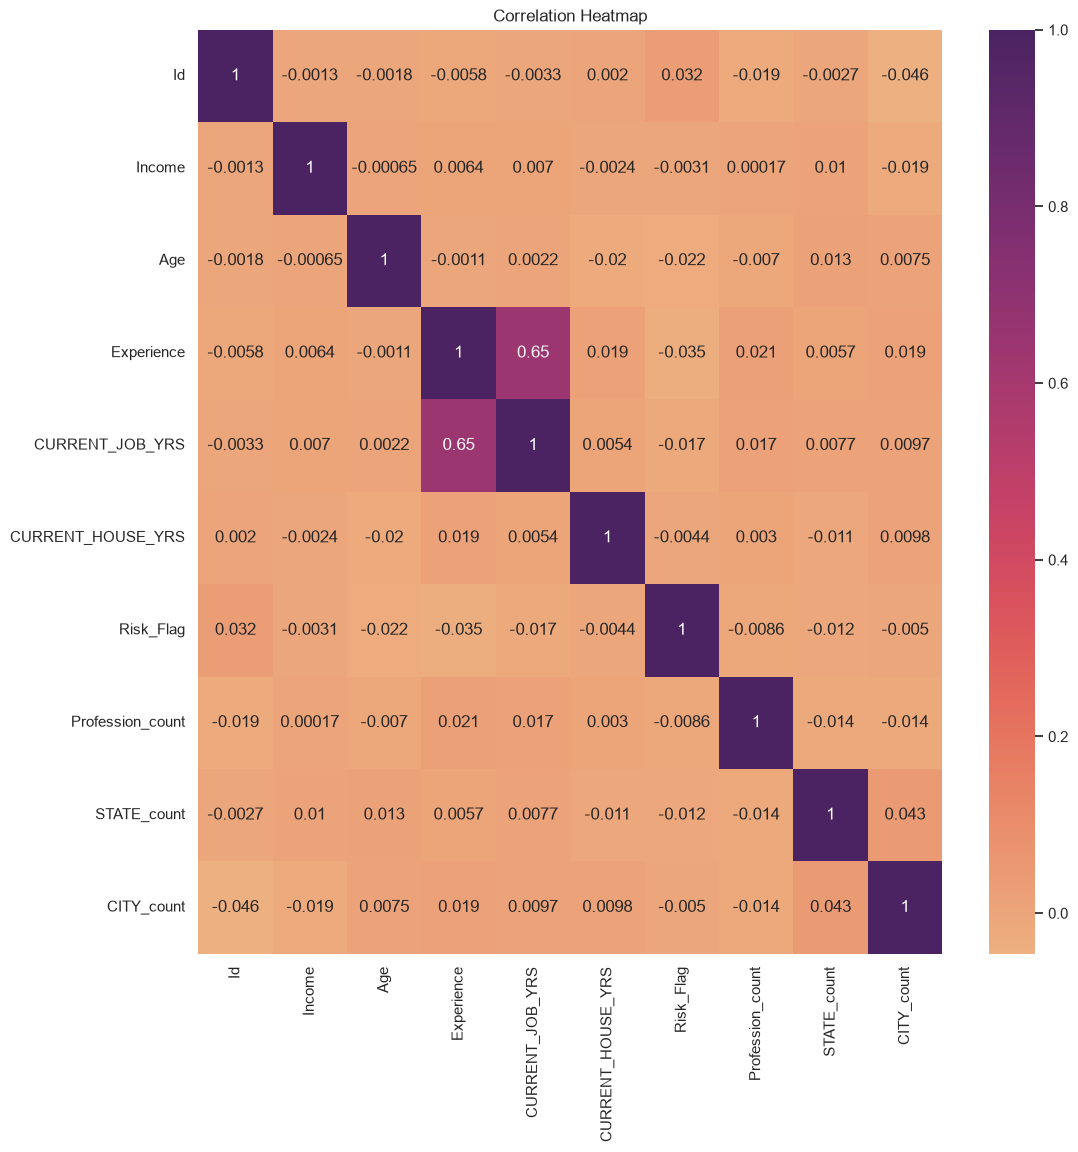

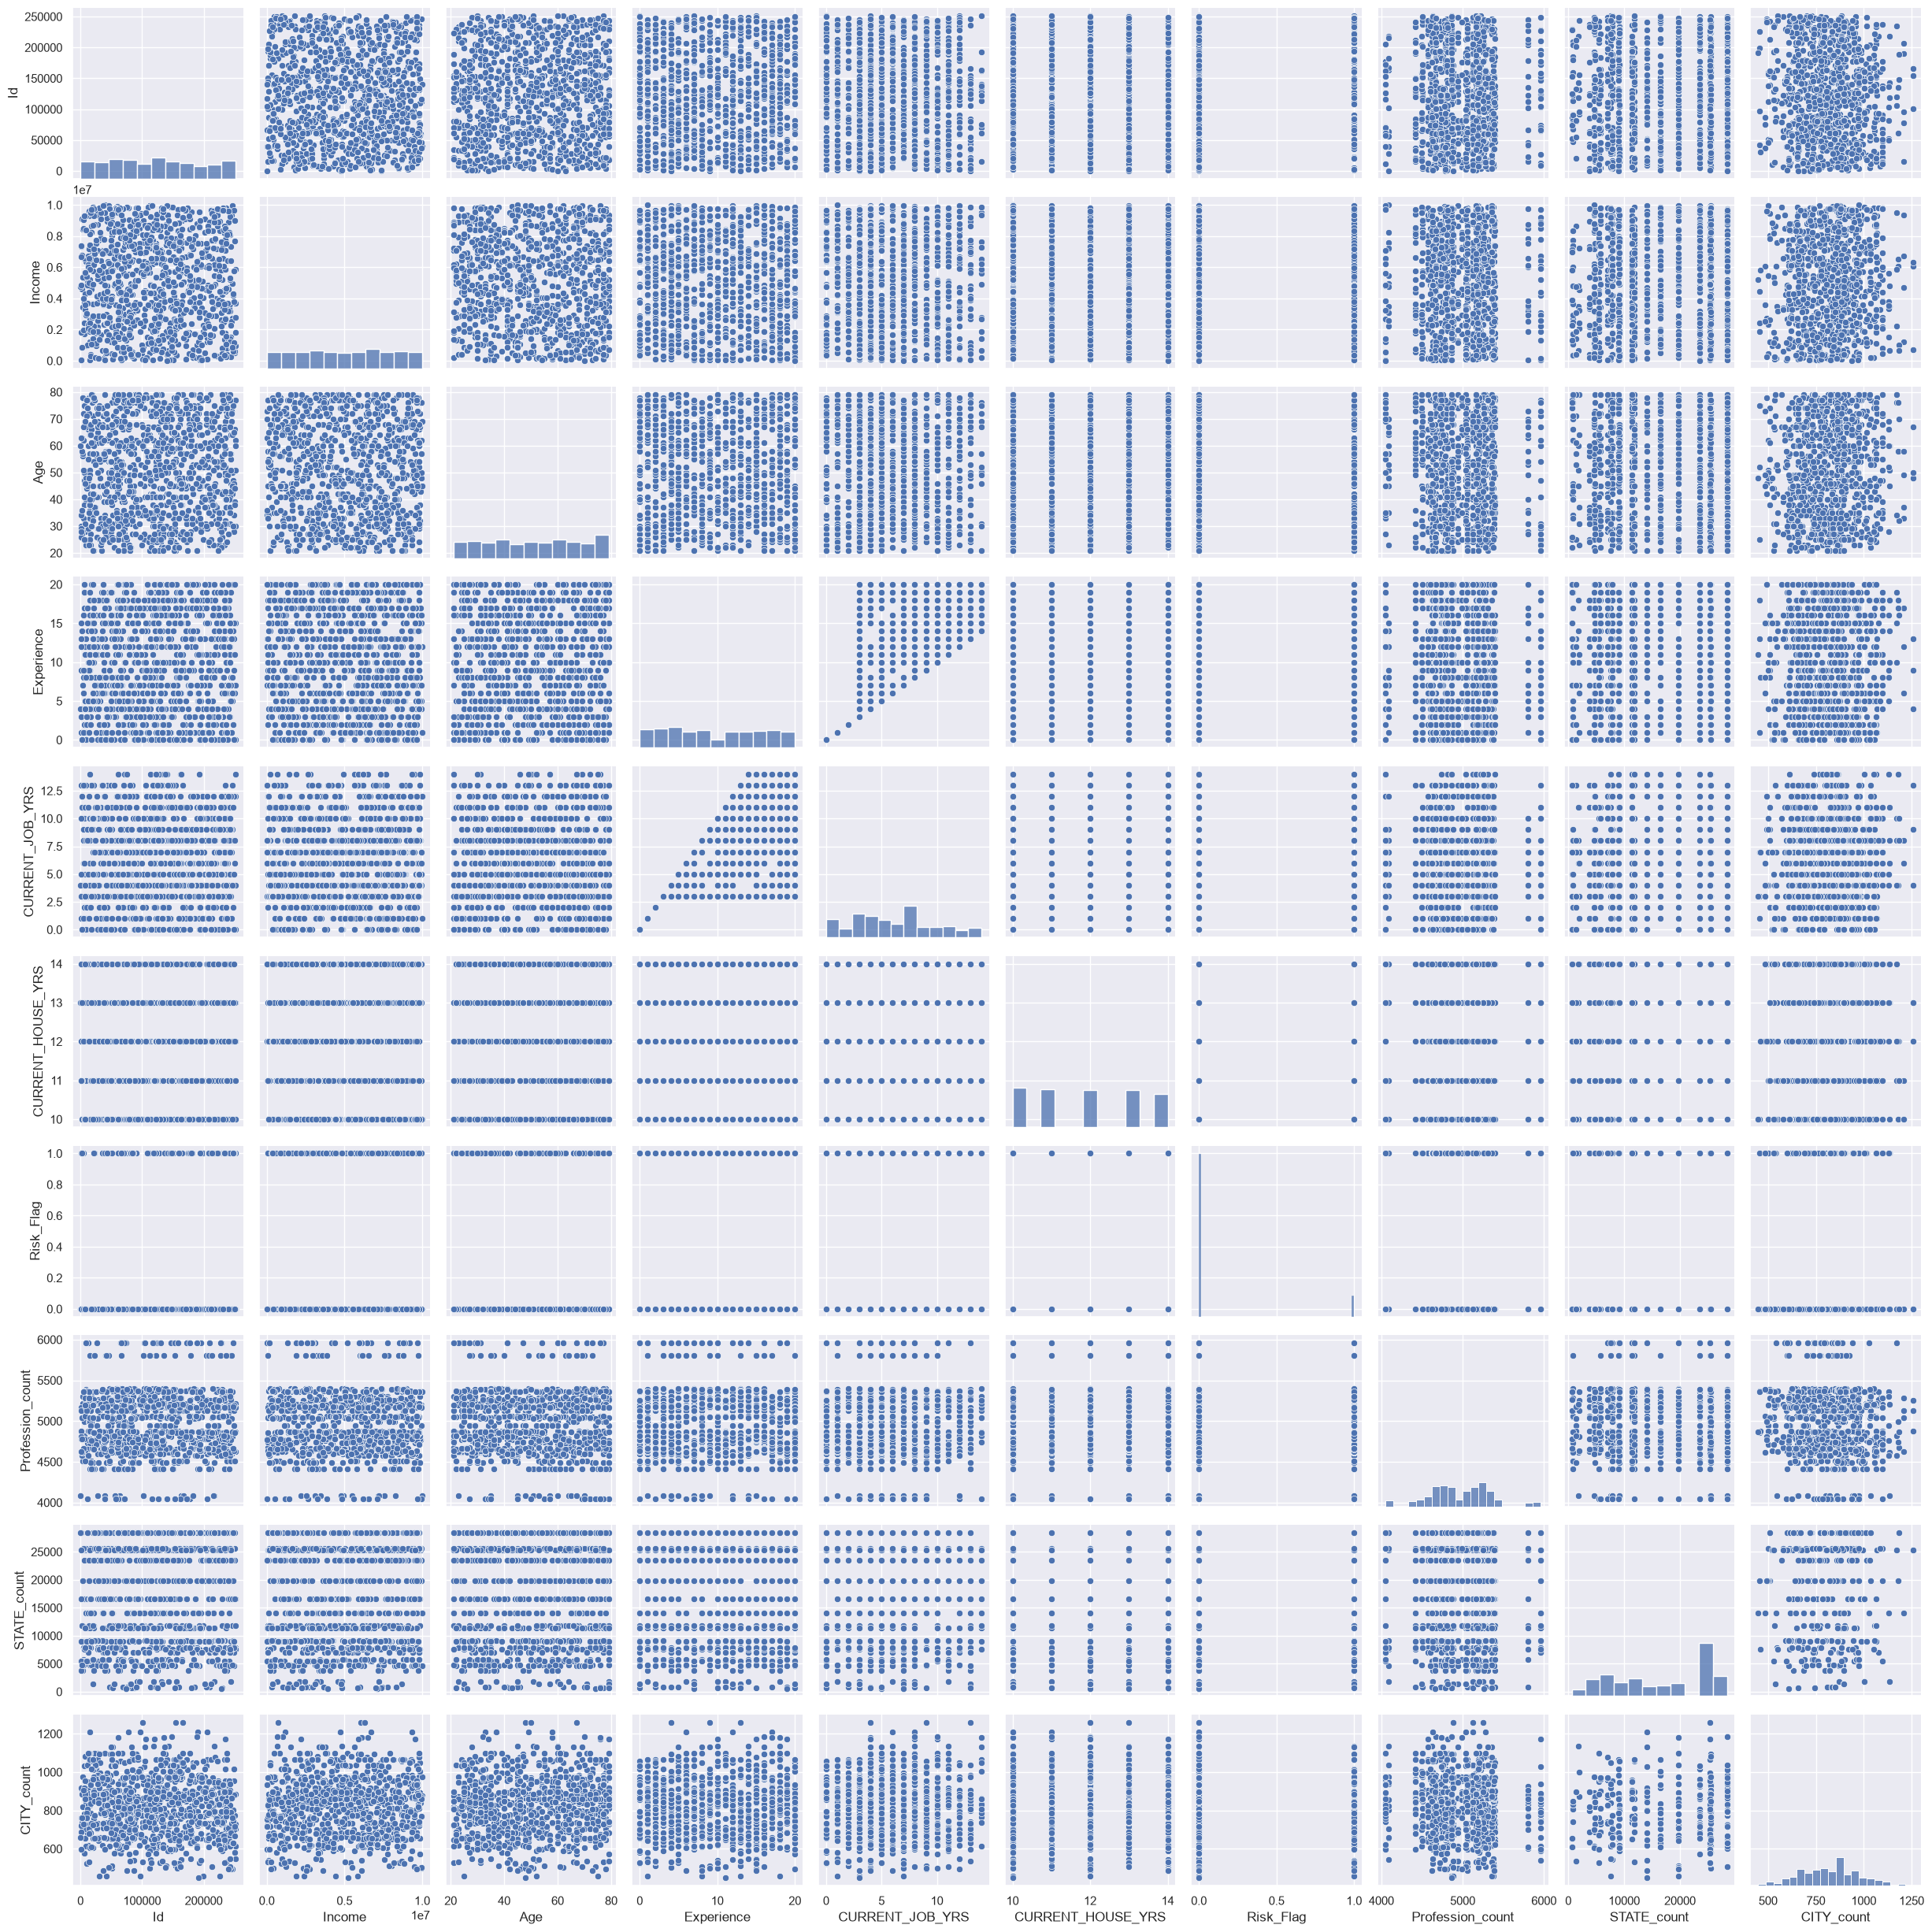

In [18]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Select only numeric columns
numeric_df = df.select_dtypes(include=[np.number])

# Plot correlation heatmap
plt.figure(figsize=(12, 12))
corr_matrix = numeric_df.corr()
sns.heatmap(corr_matrix, annot=True, cmap='flare', annot_kws={"size": 12})
plt.title('Correlation Heatmap')
plt.show()

# Sample a subset of the data for pairplot (e.g., 1000 rows)
sampled_df = numeric_df.sample(n=1000, random_state=42)
sns.pairplot(sampled_df)
plt.show()


In [19]:
from sklearn.model_selection import train_test_split

X = df.drop('Risk_Flag', axis=1)
y = df['Risk_Flag']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=7
)

In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_score


Dataset shape: (252000, 13)
<class 'pandas.DataFrame'>
RangeIndex: 252000 entries, 0 to 251999
Data columns (total 13 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   Id                 252000 non-null  int64
 1   Income             252000 non-null  int64
 2   Age                252000 non-null  int64
 3   Experience         252000 non-null  int64
 4   Married/Single     252000 non-null  str  
 5   House_Ownership    252000 non-null  str  
 6   Car_Ownership      252000 non-null  str  
 7   CURRENT_JOB_YRS    252000 non-null  int64
 8   CURRENT_HOUSE_YRS  252000 non-null  int64
 9   Risk_Flag          252000 non-null  int64
 10  Profession_count   252000 non-null  int64
 11  STATE_count        252000 non-null  int64
 12  CITY_count         252000 non-null  int64
dtypes: int64(10), str(3)
memory usage: 28.5 MB
None
Class distribution:
 Risk_Flag
0    221004
1     30996
Name: count, dtype: int64
Sampling down to 5000 rows for fa

C:\Users\RACHANA\AppData\Local\Temp\ipykernel_20900\2534893396.py:29: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()


After SMOTE, training set size: (7000, 16)
Training RandomForestClassifier...
Training complete.
📊 Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.96      0.92       875
           1       0.34      0.14      0.20       125

    accuracy                           0.86      1000
   macro avg       0.61      0.55      0.56      1000
weighted avg       0.82      0.86      0.83      1000

🧮 Confusion Matrix:


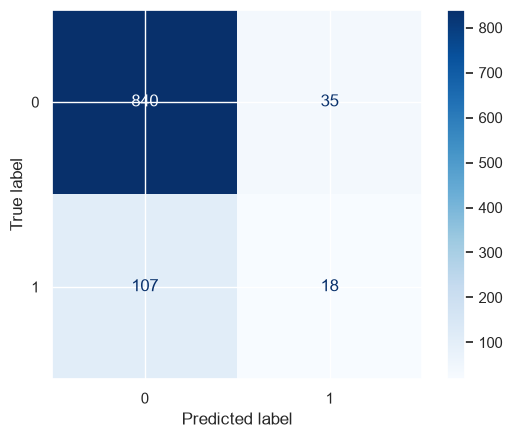

In [21]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from imblearn.over_sampling import SMOTE

print("Dataset shape:", df.shape)
print(df.info())
print("Class distribution:\n", df['Risk_Flag'].value_counts())

MAX_ROWS = 5000
if len(df) > MAX_ROWS:
    print(f"Sampling down to {MAX_ROWS} rows for faster training...")
    df_sample = df.sample(MAX_ROWS, random_state=42)
else:
    df_sample = df.copy()

X = df_sample.drop('Risk_Flag', axis=1)
y = df_sample['Risk_Flag']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=7
)

categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()
numeric_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

print(f"Numeric columns: {numeric_cols}")
print(f"Categorical columns: {categorical_cols}")

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_cols),
    ('cat', categorical_transformer, categorical_cols)
])

print("Starting preprocessing...")
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
print("Preprocessing done.")

print("Starting SMOTE oversampling...")
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_processed, y_train)
print(f"After SMOTE, training set size: {X_train_resampled.shape}")

print("Training RandomForestClassifier...")
rf = RandomForestClassifier(n_estimators=10, random_state=42, n_jobs=-1)
rf.fit(X_train_resampled, y_train_resampled)
print("Training complete.")

y_pred = rf.predict(X_test_processed)

print("📊 Classification Report:")
print(classification_report(y_test, y_pred))

print("🧮 Confusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=rf.classes_)
disp.plot(cmap='Blues')


In [22]:
%pip install imbalanced-learn

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC
from sklearn.model_selection import cross_val_score

categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()
categorical_indices = [X_train.columns.get_loc(col) for col in categorical_cols]

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

numeric_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()

numeric_transformer = Pipeline([
	('imputer', SimpleImputer(strategy='mean')),
	('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
	('imputer', SimpleImputer(strategy='most_frequent')),
	('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
	('num', numeric_transformer, numeric_cols),
	('cat', categorical_transformer, categorical_cols)
])

model_pipeline = ImbPipeline([
	('preprocessor', preprocessor),
	('oversample', SMOTENC(categorical_features=categorical_indices, random_state=42)),
	('rf', RandomForestClassifier(random_state=42))
])

cv_scores = cross_val_score(model_pipeline, X_train, y_train, cv=5, scoring='accuracy')
print(f"✅ Cross-validation Accuracy (5-fold): {cv_scores.mean():.4f}")


Note: you may need to restart the kernel to use updated packages.


C:\Users\RACHANA\AppData\Local\Temp\ipykernel_20900\583989217.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()
C:\Users\RACHANA\AppData\Local\Temp\ipykernel_20900\583989217.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.p

✅ Cross-validation Accuracy (5-fold): 0.8408


## 5- Model Evaluation & Interpretation

In [24]:
%pip install shap


Note: you may need to restart the kernel to use updated packages.


In [28]:
features = [
    'Age', 'Income', 'Experience',
    'Married/Single', 'House_Ownership', 'Car_Ownership',
    'CURRENT_JOB_YRS', 'CURRENT_HOUSE_YRS',
    'Profession_count', 'STATE_count', 'CITY_count'
]

target = 'Risk_Flag'

X = df[features]
y = df[target]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [29]:
numeric_cols = [
    'Age',
    'Income',
    'Experience',
    'CURRENT_JOB_YRS',
    'CURRENT_HOUSE_YRS',
    'Profession_count',
    'STATE_count',
    'CITY_count'
]

categorical_cols = [
    'Married/Single',
    'House_Ownership',
    'Car_Ownership'
]

In [30]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
])

model_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('rf', RandomForestClassifier(
        n_estimators=50,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ))
])

model_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('rf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['Age','Income','Experience',...,'Profession_count','STATE_count', 'CITY_count']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``

In [27]:
# Clean column names
df.columns = df.columns.str.strip()


features = [
    'Age',
    'Income',
    'Married/Single',
    'Experience',
    'House_Ownership',
    'Car_Ownership',
    'CURRENT_JOB_YRS',
    'CURRENT_HOUSE_YRS',
    'Profession_count',
    'STATE_count',
    'CITY_count'
]

target = 'Risk_Flag'

X = df[features]
y = df[target]

print("Features selected:", X.columns.tolist())
print("Target:", target)
print("Dataset shape:", X.shape)

Features selected: ['Age', 'Income', 'Married/Single', 'Experience', 'House_Ownership', 'Car_Ownership', 'CURRENT_JOB_YRS', 'CURRENT_HOUSE_YRS', 'Profession_count', 'STATE_count', 'CITY_count']
Target: Risk_Flag
Dataset shape: (252000, 11)


In [31]:
y_pred = model_pipeline.predict(X_test)
y_proba = model_pipeline.predict_proba(X_test)[:, 1]

print("Predictions completed!")

Predictions completed!


Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.99      0.94     44147
           1       0.69      0.13      0.21      6253

    accuracy                           0.88     50400
   macro avg       0.79      0.56      0.57     50400
weighted avg       0.86      0.88      0.85     50400

ROC-AUC Score: 0.9180473831029405


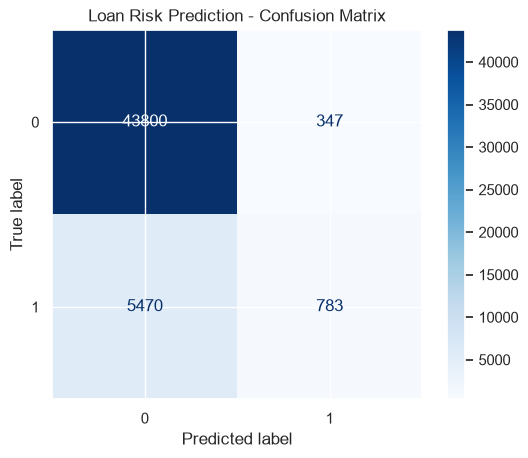

In [32]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)
import matplotlib.pyplot as plt

# Classification report
print("Classification Report:")
print(classification_report(y_test, y_pred))

# ROC-AUC score
print("ROC-AUC Score:", roc_auc_score(y_test, y_proba))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")
plt.title("Loan Risk Prediction - Confusion Matrix")
plt.show()

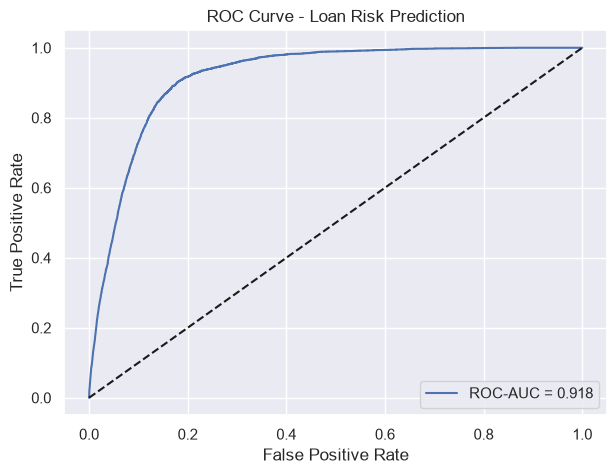

In [33]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Loan Risk Prediction")
plt.legend()
plt.show()

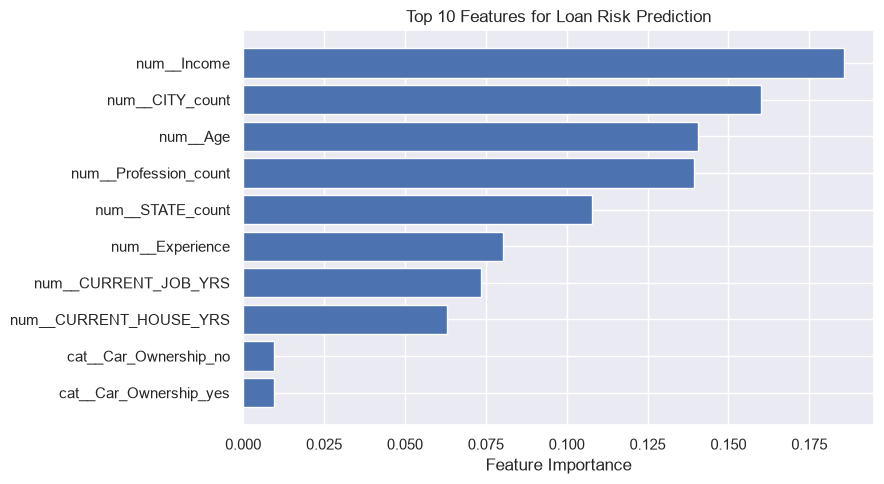

In [34]:
import numpy as np

rf = model_pipeline.named_steps["rf"]

feature_names = model_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

importances = rf.feature_importances_
indices = np.argsort(importances)[-10:]

plt.figure(figsize=(9, 5))
plt.barh(feature_names[indices], importances[indices])
plt.xlabel("Feature Importance")
plt.title("Top 10 Features for Loan Risk Prediction")
plt.tight_layout()
plt.show()

In [35]:
import joblib

joblib.dump(model_pipeline, "loan_risk_model.pkl")
print("Model saved successfully!")

Model saved successfully!
